## Building a basic Chatbot With LangGraph (GRAPH API)

### Components of LangGraph : 

1) Edges
2) Nodes
3) State

Lets load our LLM provider

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

llm = init_chat_model("groq:openai/gpt-oss-20b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000258C94A3550>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000258C94C01D0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

Lets create a chatbot node.
We will connect it to START and END of graph via Edges.

We will also create a shared state with list of messages.

In [7]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [8]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [9]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [10]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

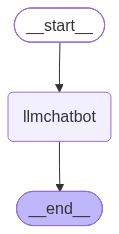

In [12]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [13]:
response=graph.invoke({"messages":"Hi"})

In [14]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [15]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hey there! I'm doing great—thanks for asking. How can I help you today?


### Chatbot With Tool

In [16]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [17]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [18]:
tools=[tool,multiply]

In [19]:
llm_with_tool=llm.bind_tools(tools)

In [20]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000258C94A3550>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000258C94C01D0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

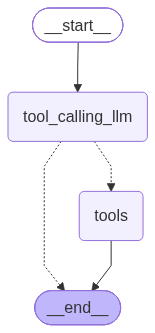

In [21]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [23]:
response['messages'][-1].content

'{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.mean.ceo/edge-ai-news-october-2026", "title": "Edge AI News | October, 2026 (STARTUP EDITION)", "content": "Multimodal AI News | October, 2026 (STARTUP EDITION)\\n\\nEdge AI news in October 2026 points to one clear pattern: the smartest AI decisions are moving out of distant data centers and into the cameras, sensors, phones, kiosks and machines that sit next to your customers. I am Violetta Bonenkamp, also known as Mean CEO. I run CADChain, a deeptech company protecting CAD and 3D data with blockchain and machine learning, and Fe/male Switch, a startup game and online incubator for women founders. From where I sit, this month’s signals carry a BUSINESS message more than a technical one. AI running locally is getting cheaper, faster and more private, and small companies that act now will collect the data, contracts and know-how that late movers will hav

In [24]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_6c0457e5-4b81-42c4-8fe9-af9b45d8ddb0)
 Call ID: fc_6c0457e5-4b81-42c4-8fe9-af9b45d8ddb0
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.mean.ceo/edge-ai-news-october-2026", "title": "Edge AI News | October, 2026 (STARTUP EDITION)", "content": "Multimodal AI News | October, 2026 (STARTUP EDITION)\n\nEdge AI news in October 2026 points to one clear pattern: the smartest AI decisions are moving out of distant data centers and into the cameras, sensors, phones, kiosks and machine

In [25]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_fa977fd2-d720-47b2-8f32-81b109e3438e)
 Call ID: fc_fa977fd2-d720-47b2-8f32-81b109e3438e
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [26]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_d73d9d46-d0dd-4e00-8f1b-7492ebd8358c)
 Call ID: fc_d73d9d46-d0dd-4e00-8f1b-7492ebd8358c
  Args:
    query: recent AI news
    search_depth: basic
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.hurriyetdailynews.com/uk-pledges-more-funding-to-guard-against-ai-risks-228556", "title": "UK pledges more funding to guard against AI risks - Latest News", "content": "Concerns about AI safety have escalated in recent months after models developed by OpenAI and Anthropic were involved in security incidents during testing, piling pressure on gove

## ReAct Agent Architecture

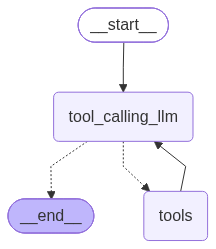

In [27]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [28]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_937c9082-7a47-4ce4-a97e-c3a312f4bb40)
 Call ID: fc_937c9082-7a47-4ce4-a97e-c3a312f4bb40
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://businessnewswales.com/new-ai-report-to-challenge-how-wales-can-turn-technology-into-economic-opportunity", "title": "New AI Report to Challenge How Wales Can Turn Technology Into Economic Opportunity", "content": "New Podcast Series to Showcase Welsh Tech Innovators25 Oct 2026New Platform to Explore How AI Can Give Wales a Competitive Advantage

### Adding Memory In Agentic Graph

In [29]:
response=graph.invoke({"messages":"Hello my name is KRish"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is KRish
================================== Ai Message ==================================

Hello KRish! 👋 How can I help you today?


In [30]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I’m not sure—could you remind me of your name?


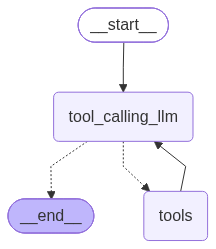

In [31]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Krish"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='87c1075a-1d4b-4047-862c-51c3c7928c6b'),
  AIMessage(content='Hi Krish! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Probably they want a greeting. There\'s no question. We can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 348, 'total_tokens': 395, 'completion_time': 0.048338432, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.016962289, 'prompt_tokens_details': None, 'queue_time': 0.397500134, 'total_time': 0.065300721}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_f102a3179c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a173fe-63d5-753f-9d09-ff85e9712c9d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens': 47, 'total_to

In [33]:
response['messages'][-1].content

'Hi Krish! How can I help you today?'

In [34]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Krish.


In [35]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Yes, you’re Krish.


### Streaming

In [36]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [37]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

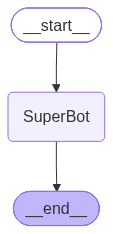

In [38]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [39]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='e091ceaf-7d49-4a03-8993-026d48a3158f'),
  AIMessage(content='Hello Krish! Great to meet you. 🎉\n\nCricket is such an exciting sport—do you have a favorite team or player? And what’s your favorite format to watch, like Tests, ODIs, or T20s?', additional_kwargs={'reasoning_content': 'The user says: "Hi,My name is Krish And I like cricket". This is a greeting, and they mention their name and interest. We should respond politely, maybe ask about cricket. There\'s no instruction that disallows us. There\'s no conflict. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 82, 'total_tokens': 196, 'completion_time': 0.131405715, 'completion_tokens_details': {'reasoning_tokens': 56}, 'prompt_time': 0.004560377, 'prompt_tokens_details': None, 'queue_time': 0.396117466, 'total_time': 0.135966092}, 'model_name': 'openai/gpt-oss-20b', 

### Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called.
- updates : This streams updates to the state of the graph after each node is called.

In [40]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Krish! 👋🏼 It’s great to meet a cricket fan. What’s your favorite aspect of the game—batting, bowling, or the strategy? And do you have a favorite team or player?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "Hi,My name is Krish And I like cricket". The system says we are ChatGPT. The developer message is empty. There\'s no instruction to do anything special. So we should respond in a friendly way, acknowledging Krish and cricket. The user didn\'t ask a question. We can greet them, ask about cricket, maybe ask what they like about it. Provide some cricket facts? Probably just respond.'}, response_metadata={'token_usage': {'completion_tokens': 144, 'prompt_tokens': 82, 'total_tokens': 226, 'completion_time': 0.153244516, 'completion_tokens_details': {'reasoning_tokens': 91}, 'prompt_time': 0.004647286, 'prompt_tokens_details': None, 'queue_time': 0.395857387, 'total_time': 0.157891802}, 'model_name': 'opena

In [41]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='c17b68a8-6295-4fb5-a57a-845f0b007c86'), AIMessage(content='Hey Krish! 👋🏼 It’s great to meet a cricket fan. What’s your favorite aspect of the game—batting, bowling, or the strategy? And do you have a favorite team or player?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "Hi,My name is Krish And I like cricket". The system says we are ChatGPT. The developer message is empty. There\'s no instruction to do anything special. So we should respond in a friendly way, acknowledging Krish and cricket. The user didn\'t ask a question. We can greet them, ask about cricket, maybe ask what they like about it. Provide some cricket facts? Probably just respond.'}, response_metadata={'token_usage': {'completion_tokens': 144, 'prompt_tokens': 82, 'total_tokens': 226, 'completion_time': 0.153244516, 'completion_tokens_details': {'reasoning_tokens': 9

In [42]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Krish! 👋 Great to meet a cricket fan. Which teams or players do you follow the most? And do you play any sports yourself?', additional_kwargs={'reasoning_content': 'The user says: "Hi,My name is Krish And I like cricket". They introduced themselves, presumably want a conversation. We should respond in a friendly manner, maybe ask about cricket. The user says "Hi, My name is Krish And I like cricket". So we respond acknowledging that. We should keep it friendly, maybe ask about what aspects of cricket they like, what teams, etc. We must not mention policies. We just respond.'}, response_metadata={'token_usage': {'completion_tokens': 133, 'prompt_tokens': 82, 'total_tokens': 215, 'completion_time': 0.147495459, 'completion_tokens_details': {'reasoning_tokens': 93}, 'prompt_time': 0.032398975, 'prompt_tokens_details': None, 'queue_time': 0.325201999, 'total_time': 0.179894434}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_

In [43]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='20830515-4caf-4ced-909e-665ed8efdd10'), AIMessage(content='Hey Krish! 👋 Great to meet a cricket fan. Which teams or players do you follow the most? And do you play any sports yourself?', additional_kwargs={'reasoning_content': 'The user says: "Hi,My name is Krish And I like cricket". They introduced themselves, presumably want a conversation. We should respond in a friendly manner, maybe ask about cricket. The user says "Hi, My name is Krish And I like cricket". So we respond acknowledging that. We should keep it friendly, maybe ask about what aspects of cricket they like, what teams, etc. We must not mention policies. We just respond.'}, response_metadata={'token_usage': {'completion_tokens': 133, 'prompt_tokens': 82, 'total_tokens': 215, 'completion_time': 0.147495459, 'completion_tokens_details': {'reasoning_tokens': 93}, 'prompt_time': 0.032398975, 'prompt_to

In [44]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a17400-6040-76cd-b08b-baf74f1f715a', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='49fc2faa-56df-4181-ac41-4e1c5cde9106')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a17400-6043-70ea-9e8b-16206f7de0bb', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:3774621d-1735-46b8-507c-6ad7f74a640c'}, 'parent_ids': ['01a17400-6040-76cd-b08b-baf74f1f715a']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':